# Counterfactual Preference Perturbation

This notebook walks through the method from the paper
[*Counterfactual Preference Perturbation Localises Objective Misalignment in Multi-Agent
LLM Negotiation*](paper/counterfactual_preference_perturbation.pdf) (AITC 2026) in three steps:

1. **What synergy measures**: the one PID concept the method rests on, shown on a toy example.
2. **The data**: behavioural features from multi-agent LLM negotiation games with
   controlled ground-truth misalignment.
3. **The perturbation sweep**: the audit itself. Perturb one agent's declared
   preferences counterfactually and watch whether the information structure responds.

Everything runs offline from data included in this repository (~1 minute of compute,
no API keys).

In [1]:
%matplotlib inline
import sys, json, copy
from pathlib import Path
from collections import defaultdict
from itertools import combinations

import numpy as np
import matplotlib.pyplot as plt

REPO = Path.cwd()
sys.path.insert(0, str(REPO / "deliberation"))
sys.path.insert(0, str(REPO / "deliberation" / "synthetic_drift"))

from pid_numpy import imin_numpy
from pairwise_pid import fit_quantile_bins, apply_bins, N_BINS, N_TARGET
from extract_features import load_scores, AGENT_KEYS
from synthetic_drift import compute_states_at_alpha

## Part 1: What synergy measures

Partial information decomposition (PID) splits the information two sources $S_1, S_2$
carry about a target $T$ into four non-negative atoms:

$$I(S_1, S_2; T) = \mathrm{Red} + \mathrm{Un}_1 + \mathrm{Un}_2 + \mathrm{Syn}$$

**Synergy** is the part visible only when both sources are observed *jointly*; neither
source carries it alone. Three tiny constructed datasets make the distinction concrete.
Each sample is a triplet $(s_1, s_2, t)$:

In [2]:
rng = np.random.default_rng(0)
bits = rng.integers(0, 2, size=(4000, 2))

cases = {
    "T = S1        (unique)":      [(a, b, a)     for a, b in bits],
    "T = S1, S2=S1 (redundant)":   [(a, a, a)     for a, _ in bits],
    "T = S1 XOR S2 (synergistic)": [(a, b, a ^ b) for a, b in bits],
}

print(f"{'case':<30} {'Red':>6} {'Un1':>6} {'Un2':>6} {'Syn':>6}")
for name, triplets in cases.items():
    at = imin_numpy(triplets)
    print(f"{name:<30} {at['Red']:>6.3f} {at['Un1']:>6.3f} {at['Un2']:>6.3f} {at['Syn']:>6.3f}")

case                              Red    Un1    Un2    Syn
T = S1        (unique)          0.000  0.999  0.000  0.000
T = S1, S2=S1 (redundant)       1.000  0.000  0.000  0.000
T = S1 XOR S2 (synergistic)     0.000  0.000  0.000  0.999


In the XOR case each source alone is useless (the target is a fair coin given either
one), yet the pair determines it exactly. That entire bit shows up as **synergy**.

Why this matters here: synergy between two agents' behavioural states (with respect to a
shared outcome) tracks *coupling* (joint structure in how the agents behave) rather
than either agent's individual informativeness. Coupling is exactly what a counterfactual
perturbation of one agent's preferences should disrupt, **if** those preferences actually
generated the behaviour.

## Part 2: The data

The negotiation benchmark ([Abdelnabi et al., 2024](https://github.com/S-Abdelnabi/LLM-Deliberation))
puts six LLM agents in a 24-round negotiation over five issues. Each agent holds a
private **score sheet** assigning points to every option of every issue; this is its
declared objective.

The controlled experiment (paper §4.1) produced three conditions:

- **control**: every agent plays under its original score sheet;
- **single mismatch**: the probed agent (*SportCo*) secretly plays with one issue's
  preferences reversed;
- **paired mismatch**: SportCo and a second agent both play with reversed preferences.

The repository ships the extracted per-game features (proposal trajectories and
per-round payoffs), so no raw transcripts or API calls are needed:

In [3]:
FEAT = REPO / "deliberation" / "collusion" / "features"

def load_games(condition):
    games = []
    for p in sorted(FEAT.glob(f"{condition}_*.json")):
        g = json.load(open(p))
        if g["n_rounds_parsed"] >= 10:
            games.append(g)
    return games

games = {c: load_games(c) for c in ["control", "single"]}
for c, gs in games.items():
    print(f"{c:>8}: {len(gs)} games, e.g. {gs[0]['game_id']} with {gs[0]['n_rounds_parsed']} parsed rounds")

scores_base, _ = load_scores()
print("\nSportCo's declared scores on Issue D:", scores_base["SportCo"][3])
print("...reversed (the counterfactual target):", list(reversed(scores_base["SportCo"][3])))

 control: 25 games, e.g. control_1 with 50 parsed rounds
  single: 15 games, e.g. single_1 with 26 parsed rounds
score sheets loaded:
  SportCo         min_thresh=55  options per issue=[3, 3, 4, 4, 5]
  union           min_thresh=50  options per issue=[3, 3, 4, 4, 5]
  mayor           min_thresh=30  options per issue=[3, 3, 4, 4, 5]
  enviroment      min_thresh=55  options per issue=[3, 3, 4, 4, 5]
  other_cities    min_thresh=31  options per issue=[3, 3, 4, 4, 5]
  DoT             min_thresh=65  options per issue=[3, 3, 4, 4, 5]

SportCo's declared scores on Issue D: [35, 29, 20, 0]
...reversed (the counterfactual target): [0, 20, 29, 35]


## Part 3: The perturbation sweep

The audit asks: **was SportCo's behaviour coupled to its declared preferences?**

We hold the behavioural logs completely fixed and interpolate SportCo's score sheet from
its declared version ($\alpha=0$) toward the Issue-D-reversed version ($\alpha=1$).
At each $\alpha$ the same logged proposals are re-encoded under the interpolated sheet,
and we compute PID synergy for every agent pair against the *non-pair welfare delta*
(how much the proposal stream helps or hurts the agents outside the pair).

The paper's core claim:

- in **control**, SportCo's behaviour was generated by the declared sheet, so moving the
  encoding away from that sheet should *disrupt* drift-pair synergy (ratio falls);
- in **single mismatch**, SportCo never played by the declared sheet, so the same
  perturbation should produce *no drop* (ratio ≈ 1).

In [4]:
DRIFT_AGENT = "SportCo"
scores_adv = copy.deepcopy(scores_base)
scores_adv[DRIFT_AGENT][3] = list(reversed(scores_base[DRIFT_AGENT][3]))
SCORE_RANGES = {a: 100 for a in AGENT_KEYS}
ALPHAS = np.linspace(0, 1, 6)

def sweep(games_list):
    # fit bin edges once, at alpha=0 (per-condition edges; see paper §3.2)
    states0, deltas0 = [], []
    for g in games_list:
        ss = compute_states_at_alpha(g, scores_base, scores_adv, 0.0,
                                     AGENT_KEYS, DRIFT_AGENT, SCORE_RANGES)
        states0.extend(ss)
        for s, sn in zip(ss, ss[1:]):
            for j, k in combinations(AGENT_KEYS, 2):
                others = [a for a in AGENT_KEYS if a not in (j, k)]
                deltas0.append(sum(sn["scores"][a] - s["scores"][a] for a in others))
    self_e = {a: fit_quantile_bins([s["self_scores"][a] for s in states0]) for a in AGENT_KEYS}
    sens_e = {a: fit_quantile_bins([s["sensitivity"][a] for s in states0]) for a in AGENT_KEYS}
    delta_e = fit_quantile_bins(deltas0, n_bins=N_TARGET)
    jbin = lambda s, a: apply_bins(s["self_scores"][a], self_e[a]) * N_BINS + \
                        apply_bins(s["sensitivity"][a], sens_e[a])

    curve = []
    for alpha in ALPHAS:
        pair_triplets = defaultdict(list)
        for g in games_list:
            ss = compute_states_at_alpha(g, scores_base, scores_adv, alpha,
                                         AGENT_KEYS, DRIFT_AGENT, SCORE_RANGES)
            for s, sn in zip(ss, ss[1:]):
                for j, k in combinations(AGENT_KEYS, 2):
                    others = [a for a in AGENT_KEYS if a not in (j, k)]
                    d = sum(sn["scores"][a] - s["scores"][a] for a in others)
                    pair_triplets[(j, k)].append((jbin(s, j), jbin(s, k), apply_bins(d, delta_e)))
        syn = [imin_numpy(t)["Syn"] for (j, k), t in pair_triplets.items()
               if DRIFT_AGENT in (j, k) and len(t) >= 10]
        curve.append(np.mean(syn))
    return np.array(curve)

curves = {c: sweep(gs) for c, gs in games.items()}

 control: endpoint ratio = 0.665
  single: endpoint ratio = 0.979


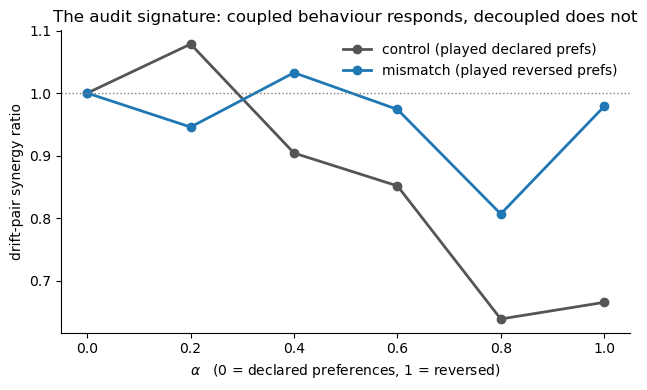

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
styles = {"control": ("#555555", "control (played declared prefs)"),
          "single":  ("#1f77b4", "mismatch (played reversed prefs)")}
for cond, curve in curves.items():
    color, label = styles[cond]
    ax.plot(ALPHAS, curve / curve[0], "o-", color=color, lw=2, label=label)
ax.axhline(1.0, color="gray", ls=":", lw=1)
ax.set_xlabel(r"$\alpha$   (0 = declared preferences, 1 = reversed)")
ax.set_ylabel("drift-pair synergy ratio")
ax.set_title("The audit signature: coupled behaviour responds, decoupled does not")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

for cond, curve in curves.items():
    print(f"{cond:>8}: endpoint ratio = {curve[-1]/curve[0]:.3f}")

The control curve falls while the mismatch curve stays near 1: the same contrast as
Figure 1 of the paper. Note that the *level* of synergy carries no signal (the mismatch
condition actually has **higher** absolute synergy); only the **response to the
counterfactual perturbation** separates the conditions.

What this notebook omitted for brevity, and where to find it:

- **cluster-bootstrap confidence intervals** (game-level resampling, 1000 draws) and the
  paired-mismatch condition: `deliberation/collusion/analyze.py`
  (headline numbers: control 0.665 [0.545, 0.768], single 0.979 [0.910, 1.133]);
- **temporal localisation**, finding *when* a mid-game preference swap happened:
  `deliberation/ceo_update/`;
- **dimension localisation**, the blind agent × issue scan: `deliberation/agent_issue_scan/`;
- **cross-environment transfer** to a common-pool resource setting: `govsim/`;
- **robustness** (binning, source/target encodings, per-issue ablation):
  `deliberation/*_sensitivity/`, `deliberation/*_ablation/`.

See the [README](README.md) for the full map.